# Weeks 2–3 — Transmon parameter sweep

**Question this notebook answers.** **Q1**: how do $T_1$, $T_\phi$ and $T_2$ vary across the
transmon design plane $(E_J, E_C)$, and where is coherence best? **Q2**: which noise channel
dominates, and where?

**Method.** 40 $E_J$ × 20 $E_C$ = 800 points, evaluated twice — once at the charge sweet spot
($n_g=0$) and once off it ($n_g=0.25$). All physics comes from `src/coherence.py`, the module
validated by `01_validation.ipynb`; this notebook does not reimplement it.

> ### Read this before quoting any number from this notebook
>
> **1. $T_2$ across this plane is very nearly a restatement of $f_{01}$.** Dielectric-loss $T_1$
> rises as the qubit frequency falls, so the "best coherence" point is simply the lowest-frequency
> point in the swept domain. Section 5 measures this confound explicitly (the correlation is
> $-0.9999$ within the transmon regime). **A raw $T_2$ maximum over this plane is not a design
> recommendation**, and Section 6 gives two defensible alternatives.
>
> **2. The unconstrained maximum is a charge qubit.** It lands near $E_J/E_C \approx 0.5$.
> Headline transmon numbers are always reported for the $E_J/E_C \ge 20$ subset — which is Koch's
> own bound (Eq. 2.13 discussion: $20 \lesssim E_J/E_C \ll 5\times10^4$).
>
> **3. $T_\phi^{\rm charge}$ at $n_g=0$ is a first-order artifact, not a prediction.** It exceeds
> $10^{13}$ µs at every point of the $n_g=0$ sweep because $\partial f_{01}/\partial n_g$ vanishes
> there. It is harmless inside the $T_2$ rate sum and must never be plotted or quoted. See
> §9.4(c) of `01_validation.ipynb`. The $n_g=0.25$ sweep exists precisely so that Q2 has a
> non-vacuous answer.

In [1]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT.name)          # name only; the absolute path is machine-specific

project root: quantum-coherence-sweet-spots-transmon-fluxonium


## 0. Setup, provenance, and the link back to validation

This notebook imports the same functions `01_validation.ipynb` tested. The assertion below is
the load-bearing one: it reproduces the validated nominal point ($E_J{=}15$, $E_C{=}0.3$,
$T_2 = 54.35$ µs) before any sweep runs. If `src/coherence.py` ever changes in a way that moves
this number, this notebook stops rather than silently producing CSVs that disagree with the
validation record.

In [2]:
import json, platform
from datetime import datetime

import numpy as np
import pandas as pd
import scqubits as scq
import matplotlib.pyplot as plt

from qubits import make_transmon, qubit_frequency, anharmonicity, TRANSMON_DEFAULTS
from coherence import transmon_coherence, DEFAULTS
import plotting as pl

scq.settings.T1_DEFAULT_WARNING = False

PROVENANCE = {
    "date": datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scqubits": scq.__version__,
    "platform": platform.platform(),
    "noise_amplitudes": {k: DEFAULTS[k] for k in ("Q_cap", "A_ng", "A_cc")},
    "units": "frequencies GHz; coherence times microseconds",
}
for k, v in PROVENANCE.items():
    print(f"{k:20s} {v}")

# --- link to 01_validation.ipynb -------------------------------------------------
VALIDATED_T2_US = 54.35208346332045      # 01_validation.ipynb, section 6
nominal = transmon_coherence(EJ=15.0, EC=0.3, ng=0.0, ncut=30)
print(f"\nnominal point T2 = {nominal['T2_us']:.6f} us "
      f"(validation record {VALIDATED_T2_US:.6f} us)")
assert abs(nominal["T2_us"] - VALIDATED_T2_US) / VALIDATED_T2_US < 1e-9, (
    "src/coherence.py no longer reproduces the validated nominal point - "
    "re-run 01_validation.ipynb before trusting anything below.")
print("consistent with 01_validation.ipynb")

date                 2026-09-07T23:27:54
python               3.11.15
numpy                2.2.6
pandas               3.0.3
scqubits             4.3.1
platform             macOS-15.0-arm64-arm-64bit
noise_amplitudes     {'Q_cap': 1000000.0, 'A_ng': 0.0001, 'A_cc': 1e-07}
units                frequencies GHz; coherence times microseconds

nominal point T2 = 54.352083 us (validation record 54.352083 us)
consistent with 01_validation.ipynb


## 1. Basis convergence across the whole grid

`01_validation.ipynb` established `ncut=30` at one point ($E_J{=}15$, $E_C{=}0.3$). This sweep
spans $E_J/E_C$ from 0.5 to 800, and the charge-basis requirement grows with $E_J/E_C$, so
convergence is re-checked at the corners of the actual swept domain. Criterion, as in 01:
$|f_{01}(\text{ncut}{=}30) - f_{01}(\text{ncut}{=}120)| < 10^{-6}$ GHz.

In [3]:
EJ_grid = np.linspace(1, 80, 40)
EC_grid = np.linspace(0.1, 2.0, 20)

corners = [(EJ_grid[0], EC_grid[0]), (EJ_grid[-1], EC_grid[0]),
           (EJ_grid[-1], EC_grid[-1]), (EJ_grid[0], EC_grid[-1])]
rows = []
for EJ, EC in corners:
    f30 = qubit_frequency(make_transmon(EJ=EJ, EC=EC, ng=0.0, ncut=30))
    f120 = qubit_frequency(make_transmon(EJ=EJ, EC=EC, ng=0.0, ncut=120))
    rows.append({"EJ": EJ, "EC": EC, "EJ_EC": EJ / EC, "f01_ncut30": f30,
                 "abs_diff_vs_ncut120": abs(f30 - f120)})
conv = pd.DataFrame(rows)
display(conv.style.format({"EJ": "{:.2f}", "EC": "{:.2f}", "EJ_EC": "{:.1f}",
                           "f01_ncut30": "{:.6f}", "abs_diff_vs_ncut120": "{:.2e}"}))

worst = conv.abs_diff_vs_ncut120.max()
print(f"worst corner deviation: {worst:.2e} GHz")
assert worst < 1e-6, "ncut=30 is NOT converged somewhere on this grid - raise it"
print("ncut=30 converged across the full swept domain")

,EJ,EC,EJ_EC,f01_ncut30,abs_diff_vs_ncut120
0,1.00,0.10,10.0,0.789951,1.52e-14
1,80.00,0.10,800.0,7.898707,8.53e-14
2,80.00,2.00,40.0,33.644654,8.74e-13
3,1.00,2.00,0.5,8.051665,3.62e-12


worst corner deviation: 3.62e-12 GHz
ncut=30 converged across the full swept domain


## 2. The sweep

800 points at $n_g=0$ (charge sweet spot) and 800 at $n_g=0.25$ (maximally charge-sensitive —
the monotonic branch identified in §7 of `01_validation.ipynb`).

Two project rules are enforced here: **data is written before any figure code runs**, so a
plotting error never costs the sweep; and the result is checked for `NaN`/`inf` rather than
trusting a bare `try/except`. A silently failing channel returns `inf` from `safe()` in
`src/coherence.py`, which would *inflate* $T_2$ — so it is checked for explicitly.

An `anharm_GHz` column is added: the anharmonicity sets the minimum control-pulse duration, and
Section 6 needs it to express coherence as a usable gate count rather than as raw microseconds.

In [4]:
def sweep(ng):
    """Full EJ x EC sweep at fixed ng, including anharmonicity. Returns a DataFrame."""
    out = []
    for EJ in EJ_grid:
        for EC in EC_grid:
            rec = transmon_coherence(EJ=EJ, EC=EC, ng=ng, ncut=30)
            rec["anharm_GHz"] = anharmonicity(make_transmon(EJ=EJ, EC=EC, ng=ng, ncut=30))
            out.append(rec)
    return pd.DataFrame(out)


df = sweep(0.0)
df.to_csv("data/transmon_full_sweep.csv", index=False)      # SAVE before plotting
df2 = sweep(0.25)
df2.to_csv("data/transmon_sweep_ng025.csv", index=False)
print(f"{len(df)} points -> data/transmon_full_sweep.csv   (ng=0)")
print(f"{len(df2)} points -> data/transmon_sweep_ng025.csv  (ng=0.25)")

# `safe()` in src/coherence.py returns inf for a channel that fails, which contributes ZERO
# rate to the T2 sum - so a silently broken channel looks like an excellent result. Every inf
# is therefore located and justified, not merely counted.
INF_AUDIT = {}
for name, frame in (("ng=0", df), ("ng=0.25", df2)):
    n_nan = int(frame.isna().sum().sum())
    num = frame.select_dtypes("number")
    inf_by_col = np.isinf(num).sum()
    inf_by_col = inf_by_col[inf_by_col > 0]
    n_bad_T2 = int((~np.isfinite(frame.T2_us) | (frame.T2_us <= 0)).sum())
    print(f"   {name:8s} NaNs={n_nan}  non-finite/negative T2={n_bad_T2}  "
          f"infs={dict(inf_by_col) if len(inf_by_col) else 'none'}")
    assert n_nan == 0 and n_bad_T2 == 0, f"{name}: sweep produced unusable rows"

    # An inf is tolerable ONLY in a dephasing column, and only where the underlying charge
    # dispersion has fallen below what double precision can resolve (~1e-13 GHz on these
    # eigenvalues). Anywhere else it means a channel genuinely failed.
    assert set(inf_by_col.index) <= {"Tphi_ng_us", "Tphi_cc_us"}, (
        f"{name}: inf outside a dephasing column - a channel failed, T2 is overestimated")
    rows_inf = frame[np.isinf(num).any(axis=1)]
    INF_AUDIT[name] = []
    for _, r in rows_inf.iterrows():
        e0 = make_transmon(EJ=r.EJ, EC=r.EC, ng=0.0, ncut=30).eigenvals(evals_count=2)
        eh = make_transmon(EJ=r.EJ, EC=r.EC, ng=0.5, ncut=30).eigenvals(evals_count=2)
        disp = abs((eh[1] - eh[0]) - (e0[1] - e0[0]))
        print(f"      inf at EJ/EC = {r.EJ_EC:7.1f}: charge dispersion = {disp:.2e} GHz "
              f"(double-precision floor ~1e-13)")
        INF_AUDIT[name].append({"EJ": float(r.EJ), "EC": float(r.EC),
                                "EJ_EC": float(r.EJ_EC), "dispersion_GHz": float(disp)})
        assert disp < 1e-11, (
            f"inf at EJ/EC={r.EJ_EC:.0f} where dispersion={disp:.1e} GHz is still resolvable "
            "- this is a failed channel, not an underflow")
print("   all infs accounted for: charge dephasing below numerical resolution, "
      "contributes zero rate correctly")

# The Tphi_ng column at ng=0 is a first-order artifact (see the header warning).
frac = (df.Tphi_ng_us > 1e9).mean()
print(f"\nng=0: {100*frac:.0f}% of points have Tphi_charge > 1e9 us "
      f"(median {df.Tphi_ng_us.median():.2e} us)")
print("   -> artifact of the vanishing first-order derivative; never plot or quote this column")

800 points -> data/transmon_full_sweep.csv   (ng=0)
800 points -> data/transmon_sweep_ng025.csv  (ng=0.25)
   ng=0     NaNs=0  non-finite/negative T2=0  infs=none
   ng=0.25  NaNs=0  non-finite/negative T2=0  infs={'Tphi_ng_us': np.int64(1)}
      inf at EJ/EC =   739.2: charge dispersion = 8.53e-14 GHz (double-precision floor ~1e-13)
   all infs accounted for: charge dephasing below numerical resolution, contributes zero rate correctly

ng=0: 100% of points have Tphi_charge > 1e9 us (median 4.20e+14 us)
   -> artifact of the vanishing first-order derivative; never plot or quote this column


## 3. Q1 — the $T_2$ landscape, with the confound made visible

Two things are drawn on top of the $T_2$ map that a bare heatmap would hide:

- **$f_{01}$ contours.** If the $T_2$ structure simply follows these, the map is a frequency map.
- **The $E_J/E_C = 20$ boundary.** Everything below/right of it is the transmon regime; the
  region above/left is a charge qubit and its numbers must not be quoted as transmon results.

A logarithmic colour scale is required — $T_2$ spans orders of magnitude across this plane, and a
linear scale renders all structure invisible.

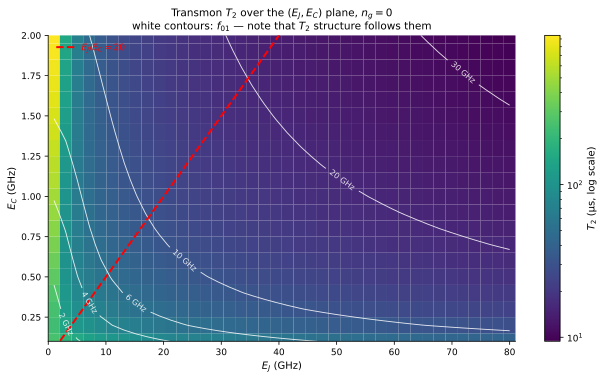

wrote figures/transmon_T2_map.png


In [5]:
pivot = df.pivot(index="EC", columns="EJ", values="T2_us")
fpivot = df.pivot(index="EC", columns="EJ", values="freq_GHz")

from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(9, 5.4))
mesh = ax.pcolormesh(pivot.columns, pivot.index, pivot.values,
                     shading="auto", norm=LogNorm(), cmap="viridis")
cb = fig.colorbar(mesh, ax=ax, label=r"$T_2$ (µs, log scale)")

cs = ax.contour(fpivot.columns, fpivot.index, fpivot.values,
                levels=[2, 4, 6, 10, 20, 30], colors="white", linewidths=0.9, alpha=0.85)
ax.clabel(cs, fmt=r"%g GHz", fontsize=8)

ejec = np.linspace(EJ_grid[0], EJ_grid[-1], 200)
ax.plot(ejec, ejec / 20.0, color="red", lw=2, ls="--", label=r"$E_J/E_C = 20$")
ax.set_ylim(EC_grid[0], EC_grid[-1])
ax.set_xlabel(r"$E_J$ (GHz)"); ax.set_ylabel(r"$E_C$ (GHz)")
ax.set_title(r"Transmon $T_2$ over the $(E_J, E_C)$ plane, $n_g = 0$" "\n"
             r"white contours: $f_{01}$ — note that $T_2$ structure follows them")
ax.legend(loc="upper left", frameon=False, labelcolor="red")
fig.tight_layout()
pl.save(fig, "figures/transmon_T2_map.png")
plt.show()
print("wrote figures/transmon_T2_map.png")

## 4. Reported maxima, and where they actually sit

Both the unconstrained maximum and the transmon-regime maximum are reported, together with the
frequency at which each occurs and whether the optimum lies on a **grid boundary**. The last
point matters: an extremum sitting on the edge of the swept domain has not been bracketed — it
is where the sweep stopped, not where the physics turns over.

In [6]:
def describe_max(frame, label, mask=None):
    sub = frame if mask is None else frame[mask]
    b = sub.loc[sub.T2_us.idxmax()]
    on_EJ_edge = bool(np.isclose(b.EJ, EJ_grid[0]) or np.isclose(b.EJ, EJ_grid[-1]))
    on_EC_edge = bool(np.isclose(b.EC, EC_grid[0]) or np.isclose(b.EC, EC_grid[-1]))
    print(f"{label}")
    print(f"   T2 = {b.T2_us:8.1f} us   EJ = {b.EJ:6.3f}  EC = {b.EC:5.3f}  "
          f"EJ/EC = {b.EJ_EC:7.2f}   f01 = {b.freq_GHz:6.3f} GHz")
    print(f"   on grid edge?  EJ: {on_EJ_edge}   EC: {on_EC_edge}"
          + ("   <-- NOT BRACKETED" if (on_EJ_edge or on_EC_edge) else ""))
    return b, (on_EJ_edge or on_EC_edge)


g_best, _ = describe_max(df, "Unconstrained maximum (NOT a transmon - do not quote):")
print()
t_best, t_on_edge = describe_max(df, "Transmon regime, EJ/EC >= 20:", mask=df.EJ_EC >= 20)

print(f"\nThermal check at 15 mK (scqubits default temperature):")
h, kB, T = 6.62607015e-34, 1.380649e-23, 0.015
for f in (t_best.freq_GHz, 4.0, 5.0):
    x = h * f * 1e9 / (kB * T)
    print(f"   f01 = {f:5.2f} GHz -> hf/kT = {x:5.2f}, thermal population = {1/(np.exp(x)-1):.4f}")

Unconstrained maximum (NOT a transmon - do not quote):
   T2 =    949.8 us   EJ =  1.000  EC = 2.000  EJ/EC =    0.50   f01 =  8.052 GHz
   on grid edge?  EJ: True   EC: True   <-- NOT BRACKETED

Transmon regime, EJ/EC >= 20:
   T2 =    187.0 us   EJ =  3.026  EC = 0.100  EJ/EC =   30.26   f01 =  1.448 GHz
   on grid edge?  EJ: False   EC: True   <-- NOT BRACKETED

Thermal check at 15 mK (scqubits default temperature):
   f01 =  1.45 GHz -> hf/kT =  4.63, thermal population = 0.0098
   f01 =  4.00 GHz -> hf/kT = 12.80, thermal population = 0.0000
   f01 =  5.00 GHz -> hf/kT = 16.00, thermal population = 0.0000


## 5. Quantifying the confound

If $T_2$ were reporting genuine design structure, it would not be predictable from $f_{01}$ alone.
The correlation below tests exactly that. A value near $-1$ means the map contains one degree of
freedom, not two — coherence is being bought with frequency, and any "sweet spot" read off it is
a statement about the noise model's frequency scaling rather than about $(E_J, E_C)$.

In [7]:
d = df.dropna()
s20 = d[d.EJ_EC >= 20]

r_all = np.corrcoef(np.log(d.T2_us), np.log(d.freq_GHz))[0, 1]
r_20 = np.corrcoef(np.log(s20.T2_us), np.log(s20.freq_GHz))[0, 1]
r_T1 = np.corrcoef(np.log(s20.T1_us), np.log(s20.freq_GHz))[0, 1]

print(f"corr(log T2, log f01), full plane      : {r_all:+.4f}")
print(f"corr(log T2, log f01), EJ/EC >= 20     : {r_20:+.4f}")
print(f"corr(log T1, log f01), EJ/EC >= 20     : {r_T1:+.4f}")
print(f"\nf01 spanned, full plane   : {d.freq_GHz.min():.2f} - {d.freq_GHz.max():.2f} GHz")
print(f"f01 spanned, EJ/EC >= 20  : {s20.freq_GHz.min():.2f} - {s20.freq_GHz.max():.2f} GHz")

if abs(r_20) > 0.99:
    print("\n>>> |corr| > 0.99: within the transmon regime T2 is a function of f01 alone.")
    print(">>> A raw T2 maximum over this plane is therefore NOT a design recommendation.")
    print(">>> Use one of the frequency-controlled metrics in Section 6 instead.")

corr(log T2, log f01), full plane      : -0.8975
corr(log T2, log f01), EJ/EC >= 20     : -0.9999
corr(log T1, log f01), EJ/EC >= 20     : -1.0000

f01 spanned, full plane   : 0.79 - 33.64 GHz
f01 spanned, EJ/EC >= 20  : 1.45 - 33.64 GHz

>>> |corr| > 0.99: within the transmon regime T2 is a function of f01 alone.
>>> A raw T2 maximum over this plane is therefore NOT a design recommendation.
>>> Use one of the frequency-controlled metrics in Section 6 instead.


## 6. Two defensible alternatives, and how the choice is settled

The raw $T_2$ maximum is not usable as a design claim. Two standard ways to remove the frequency
confound, both computed below:

**(A) Fix the frequency band.** Restrict to $3 \le f_{01} \le 6$ GHz — the range Krantz *et al.*
(2019) give as the desirable transmon operating band, set by readout hardware and by
$hf \gg k_BT$ — and ask which $(E_J, E_C)$ maximises $T_2$ *there*. Answers "given I must build at 5 GHz, what geometry is best?"

**(B) Count gates instead of microseconds.** Coherence only matters relative to how fast you can
operate. The minimum pulse duration is set by the anharmonicity, $T_{\rm gate} \sim 1/|\alpha|$
(Koch Eq. 2.13 uses exactly this argument), so

$$N_{\rm gates} \;\simeq\; \frac{T_2}{T_{\rm gate}} \;=\; 10^{3}\, T_2[\mu s]\,|\alpha|[\rm GHz].$$

This penalises the low-frequency corner automatically, because anharmonicity shrinks there too.
Answers "which design gives the most operations before decoherence?" — the question the NISQ
framing in your introduction actually poses.

**(C) Both at once.** Gate count *inside* the physical frequency band — the intersection of
(A) and (B). Computed below as well, because (A) and (B) each fail in a different direction and
the intersection is where the answer actually lives.

**These give different optima, and which one the paper leads with is a scientific choice.**
(B) is the stronger claim if the numbers support it; (A) is the more conservative one and is
easier to defend. **§6.1 settles it:** the gate-count optimum is pinned to whatever regime
threshold is imposed, so (B) alone cannot be quoted without its threshold, and the analysis adopts
(C) — gate count *inside* the Krantz frequency band and $E_J/E_C \ge 50$ envelope. §10 states the
resulting claim.

> **Assumptions behind the gate-count metric — state these in Methods.**
> $N_{\rm gates} = T_2/T_{\rm gate}$ with $T_{\rm gate} \sim 1/|\alpha|$ follows Koch *et al.*
> (2007), Sec. II C: they estimate the minimum pulse duration as
> $\tau_p \sim |\omega_{01}\alpha_r|^{-1}$ from the frequency spread of a transform-limited
> pulse, and use exactly that argument to derive the transmon-regime bound
> $20 \lesssim E_J/E_C \ll 5\times10^4$ (their Eq. 2.13 discussion, assuming a 10 ns pulse at
> $\omega_{01}/2\pi \approx 10$ GHz).
>
> It is therefore a **scaling estimate, not a gate-count prediction**. It ignores pulse shaping
> and DRAG (which relax the anharmonicity requirement), leakage to $|2\rangle$, and all
> control-hardware limits. Quote it as a relative figure of merit across designs — never as
> "this device performs $N$ gates."
>
> **The frequency band and the regime threshold both come from Krantz *et al.*, Appl. Phys.
> Rev. **6**, 021318 (2019), §II A**, which states the transmon design envelope directly:
> *"$\alpha = -E_C$ is usually designed to be 100–300 MHz, as required to maintain a desirable
> qubit frequency $\omega_q = (\sqrt{8E_JE_C}-E_C)/\hbar = 3$–$6$ GHz, while keeping an energy
> ratio sufficiently large ($E_J/E_C \ge 50$) to suppress charge sensitivity"*. The companion figure
> — *"Typical qubits are designed at frequency $\omega_q/2\pi \approx 5$ GHz"* — is from **§III B**,
> not §II A, and §III C 1 adds that below $E_J/E_C \approx 60$ the frequency itself becomes
> sensitive to **broadband** charge fluctuations.
>
> The band used here is therefore **3–6 GHz** (not the 4–6 GHz initially assumed), the
> iso-frequency cut sits at Krantz's typical **5 GHz**, and §6.1 adopts $E_J/E_C \ge 50$ with
> $|\alpha| \in [100, 300]$ MHz as the design envelope.
>
> **Limitation worth stating in Discussion.** The broadband charge sensitivity that motivates
> Krantz's $E_J/E_C \ge 50$ is *not* in this model — `tphi_1_over_f_ng` covers $1/f$ dephasing
> only. Left to itself the gate-count metric therefore under-penalises low $E_J/E_C$ and would
> recommend $E_J/E_C \approx 20$ at $|\alpha| \approx 728$ MHz, which is roughly 2.4× the
> anharmonicity anyone builds. The envelope is an external constraint on the model, not a
> result of it. Both are computed; pick one for the headline and report the other as a check.

(A) fixed 3-6 GHz band (Krantz), EJ/EC >= 20: 33 of 800 points
    best T2 =    98.0 us  at EJ = 13.154, EC = 0.100  (EJ/EC = 131.54, f01 = 3.141 GHz, alpha = -0.1081 GHz)
    on grid edge? True

(B) gate count N = 1e3 * T2[us] * |alpha|[GHz]
    best N  =     38072 gates at EJ = 41.513, EC = 2.000  (EJ/EC =  20.76, f01 = 23.586 GHz)
    its T2  =    13.4 us,  alpha = -2.8474 GHz
    on grid edge? True

(C) gate count within 3-6 GHz AND EJ/EC >= 20: 33 grid points
    best N  =     33147 gates at EJ =  9.103, EC = 0.400
    EJ/EC   =   22.76   f01 = 4.961 GHz   alpha = -0.5430 GHz   T2 =  61.0 us
    on grid edge? False


,EJ,EC,EJ_EC,freq_GHz,anharm_GHz,T2_us,N_gates
83,9.103,0.40,22.76,4.961,-0.5430,61.0,33147
62,7.077,0.30,23.59,3.795,-0.4008,78.7,31528
103,11.128,0.40,27.82,5.535,-0.5042,55.2,27838
82,9.103,0.30,30.34,4.351,-0.3699,69.6,25747
61,7.077,0.20,35.38,3.151,-0.2395,94.8,22698


    NOTE: this optimum is interior to the grid, but it sits close to the EJ/EC = 20
    constraint. That is a physical result, not an artifact - anharmonicity falls as
    (8 EJ/EC)^-1/2, so the best design is the LEAST charge-insensitive one that still
    qualifies as a transmon. Koch reaches the same conclusion from pulse-duration
    arguments (Eq. 2.13). Confirm it on a finer grid before quoting it as the result:
    current spacing is dEJ = 2.03 GHz, dEC = 0.10 GHz.

    corr(log N_gates, log f01), EJ/EC >= 20 : +0.4503   (vs -0.9999 for raw T2)
    -> the closer to 0, the more the metric reflects design rather than frequency


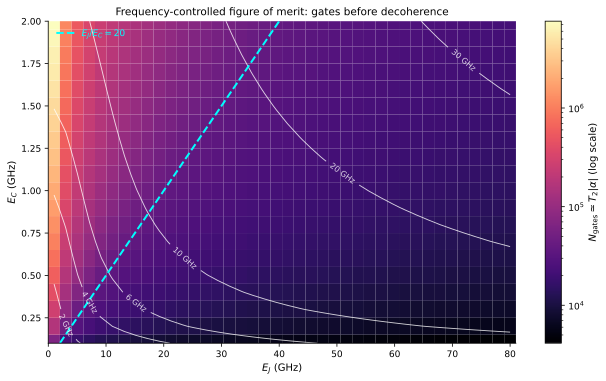

wrote figures/transmon_gatecount_map.png


In [8]:
# ---- (A) fixed frequency band -------------------------------------------------
band = d[(d.freq_GHz >= 3.0) & (d.freq_GHz <= 6.0) & (d.EJ_EC >= 20)]
print(f"(A) fixed 3-6 GHz band (Krantz), EJ/EC >= 20: {len(band)} of {len(d)} points")
if len(band):
    a = band.loc[band.T2_us.idxmax()]
    edge = np.isclose(a.EC, EC_grid[0]) or np.isclose(a.EC, EC_grid[-1]) or \
           np.isclose(a.EJ, EJ_grid[0]) or np.isclose(a.EJ, EJ_grid[-1])
    print(f"    best T2 = {a.T2_us:7.1f} us  at EJ = {a.EJ:6.3f}, EC = {a.EC:5.3f}  "
          f"(EJ/EC = {a.EJ_EC:6.2f}, f01 = {a.freq_GHz:5.3f} GHz, alpha = {a.anharm_GHz:+.4f} GHz)")
    print(f"    on grid edge? {bool(edge)}")

# ---- (B) gate count -----------------------------------------------------------
d = d.assign(N_gates=1e3 * d.T2_us * d.anharm_GHz.abs())
s20 = d[d.EJ_EC >= 20]

print(f"\n(B) gate count N = 1e3 * T2[us] * |alpha|[GHz]")
b = s20.loc[s20.N_gates.idxmax()]
edge_b = np.isclose(b.EC, EC_grid[0]) or np.isclose(b.EC, EC_grid[-1]) or \
         np.isclose(b.EJ, EJ_grid[0]) or np.isclose(b.EJ, EJ_grid[-1])
print(f"    best N  = {b.N_gates:9.0f} gates at EJ = {b.EJ:6.3f}, EC = {b.EC:5.3f}  "
      f"(EJ/EC = {b.EJ_EC:6.2f}, f01 = {b.freq_GHz:5.3f} GHz)")
print(f"    its T2  = {b.T2_us:7.1f} us,  alpha = {b.anharm_GHz:+.4f} GHz")
print(f"    on grid edge? {bool(edge_b)}")

# ---- (C) gate count INSIDE the physical frequency band ------------------------
# (A) and (B) each fail in a different direction: (A) is still driven to the lowest EC on the
# grid, and (B), left unconstrained, buys anharmonicity with frequency and lands at ~24 GHz,
# which no readout chain can address. Imposing both conditions at once is the honest version
# of the design question: "of the geometries I can actually build and address, which gives the
# most operations?"
bandC = d[(d.freq_GHz >= 3.0) & (d.freq_GHz <= 6.0) & (d.EJ_EC >= 20)]
print(f"\n(C) gate count within 3-6 GHz AND EJ/EC >= 20: {len(bandC)} grid points")
c = bandC.loc[bandC.N_gates.idxmax()]
edge_c = np.isclose(c.EC, EC_grid[0]) or np.isclose(c.EC, EC_grid[-1]) or \
         np.isclose(c.EJ, EJ_grid[0]) or np.isclose(c.EJ, EJ_grid[-1])
print(f"    best N  = {c.N_gates:9.0f} gates at EJ = {c.EJ:6.3f}, EC = {c.EC:5.3f}")
print(f"    EJ/EC   = {c.EJ_EC:7.2f}   f01 = {c.freq_GHz:5.3f} GHz   "
      f"alpha = {c.anharm_GHz:+.4f} GHz   T2 = {c.T2_us:5.1f} us")
print(f"    on grid edge? {bool(edge_c)}")
display(bandC.nlargest(5, "N_gates")[
    ["EJ", "EC", "EJ_EC", "freq_GHz", "anharm_GHz", "T2_us", "N_gates"]]
    .style.format({"EJ": "{:.3f}", "EC": "{:.2f}", "EJ_EC": "{:.2f}", "freq_GHz": "{:.3f}",
                   "anharm_GHz": "{:+.4f}", "T2_us": "{:.1f}", "N_gates": "{:.0f}"}))
print("    NOTE: this optimum is interior to the grid, but it sits close to the EJ/EC = 20")
print("    constraint. That is a physical result, not an artifact - anharmonicity falls as")
print("    (8 EJ/EC)^-1/2, so the best design is the LEAST charge-insensitive one that still")
print("    qualifies as a transmon. Koch reaches the same conclusion from pulse-duration")
print("    arguments (Eq. 2.13). Confirm it on a finer grid before quoting it as the result:")
print(f"    current spacing is dEJ = {EJ_grid[1]-EJ_grid[0]:.2f} GHz, "
      f"dEC = {EC_grid[1]-EC_grid[0]:.2f} GHz.")

r_N = np.corrcoef(np.log(s20.N_gates), np.log(s20.freq_GHz))[0, 1]
print(f"\n    corr(log N_gates, log f01), EJ/EC >= 20 : {r_N:+.4f}"
      f"   (vs {r_20:+.4f} for raw T2)")
print("    -> the closer to 0, the more the metric reflects design rather than frequency")

# ---- gate-count map -----------------------------------------------------------
npivot = d.pivot(index="EC", columns="EJ", values="N_gates")
fig, ax = plt.subplots(figsize=(9, 5.4))
mesh = ax.pcolormesh(npivot.columns, npivot.index, npivot.values,
                     shading="auto", norm=LogNorm(), cmap="magma")
fig.colorbar(mesh, ax=ax, label=r"$N_{\rm gates} \simeq T_2 |\alpha|$ (log scale)")
cs = ax.contour(fpivot.columns, fpivot.index, fpivot.values,
                levels=[2, 4, 6, 10, 20, 30], colors="white", linewidths=0.9, alpha=0.8)
ax.clabel(cs, fmt=r"%g GHz", fontsize=8)
ax.plot(ejec, ejec / 20.0, color="cyan", lw=2, ls="--", label=r"$E_J/E_C = 20$")
ax.set_ylim(EC_grid[0], EC_grid[-1])
ax.set_xlabel(r"$E_J$ (GHz)"); ax.set_ylabel(r"$E_C$ (GHz)")
ax.set_title(r"Frequency-controlled figure of merit: gates before decoherence")
ax.legend(loc="upper left", frameon=False, labelcolor="cyan")
fig.tight_layout()
pl.save(fig, "figures/transmon_gatecount_map.png")
plt.show()
print("wrote figures/transmon_gatecount_map.png")

### 6.1 Fine-grid confirmation — is the optimum real, or set by where the line is drawn?

The coarse grid puts the (C) optimum near the $E_J/E_C = 20$ constraint. That raises the
question the coarse spacing cannot answer: **is there a genuine interior maximum in $E_J/E_C$,
or does the figure of merit simply increase all the way down to the transmon-regime boundary?**

The distinction matters for what the paper can claim:

- *Interior maximum* → "there is an optimal $E_J/E_C$" — a design sweet spot.
- *Monotone to the boundary* → "there is no interior optimum; the best transmon is the least
  charge-insensitive one that still qualifies" — a design **trade-off**, and the reported
  number then depends entirely on where the regime boundary is drawn.

The test: refine to $\Delta E_J = 0.25$, $\Delta E_C = 0.01$ GHz over $E_J \in [4,20]$,
$E_C \in [0.08,0.60]$ — a $65 \times 53 = 3445$-point grid — then re-locate the optimum under
**eight different** threshold choices spanning $E_J/E_C = 15$ to $60$.
If the optimum tracks the threshold, it is pinned to the constraint and the second reading is
the correct one. The threshold is also taken from *your own* $n_g=0.25$ data (where charge
noise stops dominating), not only from Koch.

fine grid: 65 x 53 = 3445 points (dEJ = 0.25, dEC = 0.01 GHz)


3445 points -> data/transmon_fine_grid.csv
points inside the Krantz 3.0-6.0 GHz band: 2056

three candidate thresholds for the transmon regime:
   Koch 2007 (pulse-duration bound)             : EJ/EC >= 20
   this work (charge-dominance crossover, sec 7): EJ/EC >= 25.3
   Krantz 2019 (engineering design practice)    : EJ/EC >= 50



,threshold,best_EJ,best_EC,best_EJ_EC,f01_GHz,alpha_MHz,T2_us,N_gates,EJ_EC_minus_threshold
0,15.0,9.00,0.600,15.00,5.916,1086,51.4,55764,0.00
1,20.0,10.00,0.500,20.00,5.777,728,52.7,38333,0.00
2,25.0,11.25,0.450,25.00,5.875,587,52.0,30564,0.00
3,25.3,11.50,0.450,25.56,5.946,583,51.5,29987,0.24
4,30.0,12.00,0.400,30.00,5.765,495,53.2,26288,0.00
5,40.0,14.00,0.350,40.00,5.888,412,52.3,21561,0.00
6,50.0,15.50,0.310,50.00,5.872,356,52.6,18757,0.00
7,60.0,16.25,0.270,60.19,5.640,305,54.9,16769,0.19


max distance of the optimum from its threshold: 0.24

>>> PINNED, across thresholds spanning 15 to 60. There is NO interior optimum in
>>> EJ/EC: at fixed frequency, gate count increases monotonically as EJ/EC falls.
>>> The correct claim is a TRADE-OFF, not a sweet spot, and any quoted optimum is
>>> meaningful only together with the threshold it assumed.

iso-frequency cut at Krantz's typical design point: f01 = 5.0 +/- 0.05 GHz -> 74 points, EJ/EC from 11.4 to 117.6
   T2       : 59.66 - 62.56 us  (spread 4.8%)
   |alpha|  : 185 - 1353 MHz  (factor 7.3)
   N_gates  : 11410 - 81482  (factor 7.1)
   -> at fixed frequency, T2 is flat to a few percent while anharmonicity falls by
      a factor of 7: the trade-off is ENTIRELY anharmonicity.


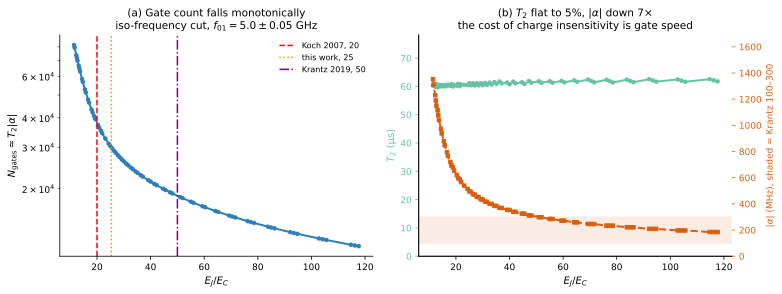

wrote figures/transmon_tradeoff.png

Is the charge-dominance crossover stable against the assumed noise amplitudes?
   baseline (Q_cap=1e6, A_ng=1e-4)    -> crossover EJ/EC =  25.31


   Q_cap = 3e5  (Nguyen-measured)     -> crossover EJ/EC =  20.81
   A_ng  = 3e-4 (3x noisier)          -> crossover EJ/EC =  29.87


   A_ng  = 3e-5 (3x quieter)          -> crossover EJ/EC =  20.81

   crossover spans 20.8 - 29.9 (spread 9.1) under literature noise variation
   -> noise-dependent, so it is reported as a RESULT of Q2, not used as an input.

>>> ADOPTED: the Krantz 2019 design envelope -
      EJ/EC >= 50, |alpha| in 100-300 MHz, f01 in 3.0-6.0 GHz   (665 of 3445 grid points)
    Reasons: (i) it is independent of every noise amplitude in this study, so it holds
    fixed while Week 5 varies them; (ii) it reflects current engineering practice
    rather than a 2007 theory bound; (iii) it is the most conservative of the three.

    Q1 operating point: EJ = 13.00 GHz, EC = 0.260 GHz (EJ/EC = 50.0)
      f01 = 4.92 GHz, T2 = 62.4 us, |alpha| = 299 MHz, N = 18652 gates

    For contrast, the unconstrained-by-Krantz optimum at EJ/EC >= 20 would be
      EJ/EC = 20.0, |alpha| = 728 MHz, N = 38333 gates
    - a 2.1x higher gate count, but at an anharmonicity
    2.4x above what Krantz says is built.
    LIMI

In [9]:
# Grid extended to EC = 0.08 GHz so that Krantz's EJ/EC >= 50 is reachable at a realistic
# anharmonicity (|alpha| = EC = 100-300 MHz) rather than pressed against a grid edge.
EJ_fine = np.arange(4.0, 20.001, 0.25)
EC_fine = np.arange(0.08, 0.6001, 0.01)
print(f"fine grid: {len(EJ_fine)} x {len(EC_fine)} = {len(EJ_fine)*len(EC_fine)} points "
      f"(dEJ = 0.25, dEC = 0.01 GHz)")

fine = []
for EJ in EJ_fine:
    for EC in EC_fine:
        rec = transmon_coherence(EJ=float(EJ), EC=float(EC), ng=0.0, ncut=30)
        rec["anharm_GHz"] = anharmonicity(
            make_transmon(EJ=float(EJ), EC=float(EC), ng=0.0, ncut=30))
        fine.append(rec)
fine = pd.DataFrame(fine)
fine["N_gates"] = 1e3 * fine.T2_us * fine.anharm_GHz.abs()
fine.to_csv("data/transmon_fine_grid.csv", index=False)          # SAVE before plotting
assert fine.isna().sum().sum() == 0 and np.isfinite(fine.T2_us).all()
print(f"{len(fine)} points -> data/transmon_fine_grid.csv")

# Krantz et al. (2019), Sec. II A: "alpha = -EC is usually designed to be 100-300 MHz, as
# required to maintain a desirable qubit frequency wq = (sqrt(8 EJ EC) - EC)/hbar = 3-6 GHz,
# while keeping an energy ratio sufficiently large (EJ/EC >= 50) to suppress charge
# sensitivity"; and "Typical qubits are designed at frequency wq/2pi ~ 5 GHz".
F_LO, F_HI = 3.0, 6.0
ALPHA_LO_MHZ, ALPHA_HI_MHZ = 100.0, 300.0
BAND = (fine.freq_GHz >= F_LO) & (fine.freq_GHz <= F_HI)
print(f"points inside the Krantz {F_LO}-{F_HI} GHz band: {int(BAND.sum())}")

# --- does the optimum move when the regime threshold moves? ---------------------
# Threshold from THIS project's own ng=0.25 sweep: the largest EJ/EC at which charge noise
# is still the dominant channel. Computed inline here because section 7 runs later.
_rates25 = pd.DataFrame({"relaxation": 1 / (2 * df2.T1_us),
                         "charge": 1 / df2.Tphi_ng_us,
                         "crit-current": 1 / df2.Tphi_cc_us})
charge_thresh = float(df2.EJ_EC[_rates25.idxmax(axis=1) == "charge"].max())
print(f"\nthree candidate thresholds for the transmon regime:")
print(f"   Koch 2007 (pulse-duration bound)             : EJ/EC >= 20")
print(f"   this work (charge-dominance crossover, sec 7): EJ/EC >= {charge_thresh:.1f}")
print(f"   Krantz 2019 (engineering design practice)    : EJ/EC >= 50\n")

rows = []
for t in [15, 20, 25, charge_thresh, 30, 40, 50, 60]:
    sub = fine[BAND & (fine.EJ_EC >= t)]
    if not len(sub):
        continue
    b = sub.loc[sub.N_gates.idxmax()]
    rows.append({"threshold": t, "best_EJ": b.EJ, "best_EC": b.EC, "best_EJ_EC": b.EJ_EC,
                 "f01_GHz": b.freq_GHz, "alpha_MHz": 1e3 * abs(b.anharm_GHz),
                 "T2_us": b.T2_us, "N_gates": b.N_gates,
                 "EJ_EC_minus_threshold": b.EJ_EC - t})
pin = pd.DataFrame(rows)
display(pin.style.format({"threshold": "{:.1f}", "best_EJ": "{:.2f}", "best_EC": "{:.3f}",
                          "best_EJ_EC": "{:.2f}", "f01_GHz": "{:.3f}", "alpha_MHz": "{:.0f}",
                          "T2_us": "{:.1f}", "N_gates": "{:.0f}",
                          "EJ_EC_minus_threshold": "{:.2f}"}))

gap = pin.EJ_EC_minus_threshold.abs().max()
pinned = gap < 2.0
print(f"max distance of the optimum from its threshold: {gap:.2f}")
if pinned:
    print("\n>>> PINNED, across thresholds spanning 15 to 60. There is NO interior optimum in")
    print(">>> EJ/EC: at fixed frequency, gate count increases monotonically as EJ/EC falls.")
    print(">>> The correct claim is a TRADE-OFF, not a sweet spot, and any quoted optimum is")
    print(">>> meaningful only together with the threshold it assumed.")
else:
    print("\n>>> INTERIOR optimum: it does not track the threshold.")

# --- the trade-off curve, at FIXED frequency ------------------------------------
# Binning across the whole band is not a controlled comparison: T2 correlates with f01 at
# about -0.99 *within* the band, so such a curve mixes frequencies and the frequency
# dependence swamps the EJ/EC dependence. Hold f01 fixed at Krantz's "typical" 5 GHz.
F0, FTOL = 5.0, 0.05
iso = fine[(fine.freq_GHz - F0).abs() <= FTOL].sort_values("EJ_EC")
print(f"\niso-frequency cut at Krantz's typical design point: f01 = {F0} +/- {FTOL} GHz "
      f"-> {len(iso)} points, EJ/EC from {iso.EJ_EC.min():.1f} to {iso.EJ_EC.max():.1f}")

t2_spread = 100 * (iso.T2_us.max() / iso.T2_us.min() - 1)
a_factor = iso.anharm_GHz.abs().max() / iso.anharm_GHz.abs().min()
n_factor = iso.N_gates.max() / iso.N_gates.min()
print(f"   T2       : {iso.T2_us.min():.2f} - {iso.T2_us.max():.2f} us  "
      f"(spread {t2_spread:.1f}%)")
print(f"   |alpha|  : {1e3*iso.anharm_GHz.abs().min():.0f} - "
      f"{1e3*iso.anharm_GHz.abs().max():.0f} MHz  (factor {a_factor:.1f})")
print(f"   N_gates  : {iso.N_gates.min():.0f} - {iso.N_gates.max():.0f}  "
      f"(factor {n_factor:.1f})")
print(f"   -> at fixed frequency, T2 is flat to a few percent while anharmonicity falls by")
print(f"      a factor of {a_factor:.0f}: the trade-off is ENTIRELY anharmonicity.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(iso.EJ_EC, iso.N_gates, "o-", color="#2c7fb8", lw=2, ms=3.5)
ax[0].axvline(20, ls="--", color="red", lw=1.5, label="Koch 2007, 20")
ax[0].axvline(charge_thresh, ls=":", color="darkorange", lw=1.5,
              label=f"this work, {charge_thresh:.0f}")
ax[0].axvline(50, ls="-.", color="purple", lw=1.5, label="Krantz 2019, 50")
ax[0].set_yscale("log")
ax[0].set_xlabel(r"$E_J/E_C$"); ax[0].set_ylabel(r"$N_{\rm gates} \simeq T_2|\alpha|$")
ax[0].set_title(rf"(a) Gate count falls monotonically" "\n"
                rf"iso-frequency cut, $f_{{01}} = {F0}\pm{FTOL}$ GHz")
ax[0].legend(frameon=False, fontsize=8)

# Colour is the ONLY cue separating the two y-axes here, so the pair must survive a CVD
# check: #31a354 vs #d95f0e collapses to two olives under deuteranopia (dE00 ~ 11, see the
# audit in src/plotting.py). CHANNEL_COLORS[2] = #66c2a5 raises the worst case to dE00 = 26.
_GREEN = pl.CHANNEL_COLORS.colors[2]
ax[1].plot(iso.EJ_EC, iso.T2_us, "o-", color=_GREEN, lw=2, ms=3.5)
ax[1].set_ylim(0, 1.25 * iso.T2_us.max())
ax2 = ax[1].twinx()
ax2.plot(iso.EJ_EC, 1e3 * iso.anharm_GHz.abs(), "s--", color="#d95f0e", lw=2, ms=3.5)
ax2.axhspan(ALPHA_LO_MHZ, ALPHA_HI_MHZ, color="#d95f0e", alpha=0.12)
ax2.set_ylim(0, 1.25 * 1e3 * iso.anharm_GHz.abs().max())
ax[1].set_xlabel(r"$E_J/E_C$")
ax[1].set_ylabel(r"$T_2$ (µs)", color=_GREEN)
ax2.set_ylabel(r"$|\alpha|$ (MHz), shaded = Krantz 100–300", color="#d95f0e", fontsize=9)
ax[1].tick_params(axis="y", colors=_GREEN); ax2.tick_params(axis="y", colors="#d95f0e")
ax[1].set_title(rf"(b) $T_2$ flat to {t2_spread:.0f}%, $|\alpha|$ down {a_factor:.0f}$\times$"
                "\n" r"the cost of charge insensitivity is gate speed")
for a in (ax[0], ax[1]):
    a.spines[["top"]].set_visible(False)
fig.tight_layout()
pl.save(fig, "figures/transmon_tradeoff.png")
plt.show()
print("wrote figures/transmon_tradeoff.png")

# --- which threshold should the paper adopt? -----------------------------------
# The optimum is pinned to whichever threshold is imposed, so the threshold IS the headline
# number. Candidates differ in KIND: this project's crossover depends on the assumed noise
# amplitudes; Koch's and Krantz's do not. Week 5 varies exactly those amplitudes, so a
# noise-dependent threshold would drag the Q1 operating point around during the robustness
# test. Test that directly.
print("\nIs the charge-dominance crossover stable against the assumed noise amplitudes?")
stability = []
for label, kw in [("baseline (Q_cap=1e6, A_ng=1e-4)", {}),
                  ("Q_cap = 3e5  (Nguyen-measured)", {"Q_cap": 3e5}),
                  ("A_ng  = 3e-4 (3x noisier)", {"A_ng": 3e-4}),
                  ("A_ng  = 3e-5 (3x quieter)", {"A_ng": 3e-5})]:
    rows_s = [transmon_coherence(EJ=EJ, EC=EC, ng=0.25, ncut=30, **kw)
              for EJ in EJ_grid for EC in EC_grid]
    ds = pd.DataFrame(rows_s)
    rs = pd.DataFrame({"relax": 1 / (2 * ds.T1_us), "charge": 1 / ds.Tphi_ng_us,
                       "cc": 1 / ds.Tphi_cc_us})
    dm = rs.idxmax(axis=1)
    cross = float(ds.EJ_EC[dm == "charge"].max()) if (dm == "charge").any() else float("nan")
    stability.append({"assumption": label, "crossover_EJ_EC": cross})
    print(f"   {label:34s} -> crossover EJ/EC = {cross:6.2f}")

stab = pd.DataFrame(stability)
spread = stab.crossover_EJ_EC.max() - stab.crossover_EJ_EC.min()
print(f"\n   crossover spans {stab.crossover_EJ_EC.min():.1f} - "
      f"{stab.crossover_EJ_EC.max():.1f} (spread {spread:.1f}) under literature noise variation")
print("   -> noise-dependent, so it is reported as a RESULT of Q2, not used as an input.")

# --- adopted design envelope: all three Krantz constraints at once --------------
ADOPTED_THRESHOLD = 50          # Krantz 2019
env_mask = (BAND & (fine.EJ_EC >= ADOPTED_THRESHOLD)
            & (1e3 * fine.anharm_GHz.abs() >= ALPHA_LO_MHZ)
            & (1e3 * fine.anharm_GHz.abs() <= ALPHA_HI_MHZ))
envelope = fine[env_mask]
op = envelope.nlargest(1, "N_gates").iloc[0]
print(f"\n>>> ADOPTED: the Krantz 2019 design envelope -")
print(f"      EJ/EC >= {ADOPTED_THRESHOLD}, |alpha| in {ALPHA_LO_MHZ:.0f}-{ALPHA_HI_MHZ:.0f} MHz, "
      f"f01 in {F_LO}-{F_HI} GHz   ({len(envelope)} of {len(fine)} grid points)")
print(f"    Reasons: (i) it is independent of every noise amplitude in this study, so it holds")
print(f"    fixed while Week 5 varies them; (ii) it reflects current engineering practice")
print(f"    rather than a 2007 theory bound; (iii) it is the most conservative of the three.")
print(f"\n    Q1 operating point: EJ = {op.EJ:.2f} GHz, EC = {op.EC:.3f} GHz "
      f"(EJ/EC = {op.EJ_EC:.1f})")
print(f"      f01 = {op.freq_GHz:.2f} GHz, T2 = {op.T2_us:.1f} us, "
      f"|alpha| = {1e3*abs(op.anharm_GHz):.0f} MHz, N = {op.N_gates:.0f} gates")

koch_op = fine[BAND & (fine.EJ_EC >= 20)].nlargest(1, "N_gates").iloc[0]
print(f"\n    For contrast, the unconstrained-by-Krantz optimum at EJ/EC >= 20 would be")
print(f"      EJ/EC = {koch_op.EJ_EC:.1f}, |alpha| = {1e3*abs(koch_op.anharm_GHz):.0f} MHz, "
      f"N = {koch_op.N_gates:.0f} gates")
print(f"    - a {koch_op.N_gates/op.N_gates:.1f}x higher gate count, but at an anharmonicity")
print(f"    {1e3*abs(koch_op.anharm_GHz)/ALPHA_HI_MHZ:.1f}x above what Krantz says is built.")
print(f"    LIMITATION: our noise model contains no broadband charge sensitivity, which is the")
print(f"    effect Krantz cites for requiring EJ/EC >= 50 (and ~60). The model alone therefore")
print(f"    under-penalises low EJ/EC. State this in Discussion.")

with open("data/transmon_fine_grid_metadata.json", "w") as fh:
    json.dump({
        "notebook": "notebooks/02_transmon_sweep.ipynb (section 6.1)",
        "purpose": "test whether the gate-count optimum is interior or pinned to the "
                   "transmon-regime threshold, and fix the adopted design envelope",
        "provenance": PROVENANCE,
        "grid": {"EJ_GHz": [4.0, 20.0, 0.25], "EC_GHz": [0.08, 0.6, 0.01],
                 "points": int(len(fine)), "ng": 0.0, "ncut": 30},
        "frequency_band_GHz": [F_LO, F_HI],
        "thresholds_tested": [float(t) for t in pin.threshold],
        "charge_threshold_from_this_work": charge_thresh,
        "adopted_design_envelope": {
            "EJ_EC_min": ADOPTED_THRESHOLD,
            "alpha_MHz": [ALPHA_LO_MHZ, ALPHA_HI_MHZ],
            "f01_GHz": [F_LO, F_HI],
            "source": "Krantz et al., Appl. Phys. Rev. 6, 021318 (2019), Sec. II A "
                      "(design envelope); the 5 GHz typical-design figure is Sec. III B",
            "reason": "independent of the assumed noise amplitudes; reflects current "
                      "engineering practice; most conservative of the three candidates",
            "operating_point": {"EJ": float(op.EJ), "EC": float(op.EC),
                                "EJ_EC": float(op.EJ_EC), "f01_GHz": float(op.freq_GHz),
                                "T2_us": float(op.T2_us),
                                "anharm_MHz": float(1e3 * abs(op.anharm_GHz)),
                                "N_gates": float(op.N_gates)},
        },
        "threshold_stability": {
            "note": "this project's charge-dominance crossover is a RESULT, not an assumption; "
                    "it moves with the noise model and is reported as corroboration only",
            "values": stability, "spread": float(spread),
        },
        "known_limitation": "the noise model contains no broadband charge sensitivity, the "
                            "effect Krantz cites for requiring EJ/EC >= 50; the gate-count "
                            "metric alone therefore under-penalises low EJ/EC",
        "verdict": "pinned to threshold - no interior optimum" if pinned
                   else "interior optimum exists",
        "max_distance_from_threshold": float(gap),
        "outputs": ["data/transmon_fine_grid.csv", "figures/transmon_tradeoff.png"],
    }, fh, indent=2, default=str)
print("\nwrote data/transmon_fine_grid_metadata.json")

## 7. Q2 — dominant noise channel

**At $n_g = 0$ this question has no content.** Charge dephasing is switched off by symmetry, so
relaxation dominates at all 800 points by construction; a map of it would be a single flat colour
and would say nothing about noise. The meaningful map is at $n_g = 0.25$, where the transmon is
maximally charge-sensitive — the physically relevant case for a device whose offset charge drifts.

Both are tabulated below so the contrast is on the record, but only the $n_g=0.25$ map is
plotted, and only channels that actually occur are drawn.

dominant channel, ng=0    : {'relaxation': np.int64(800)}
dominant channel, ng=0.25 : {'relaxation': np.int64(535), 'charge': np.int64(265)}

FINDING: ['crit-current'] never dominates anywhere in the swept domain
   (at the literature amplitudes used here; report this rather than hiding it)


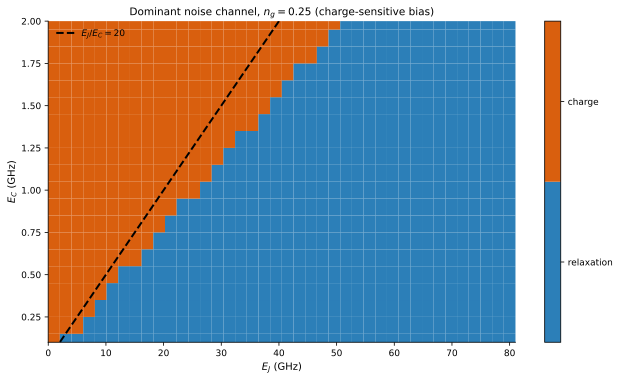


charge-dominated region: EJ/EC from 0.50 to 25.31  (265 of 800 points)
   -> charge noise ceases to dominate above EJ/EC ~ 25, consistent with Koch's transmon-regime bound of 20


In [10]:
def dominant_counts(frame):
    rates = pd.DataFrame({
        "relaxation": 1 / (2 * frame.T1_us),
        "charge": 1 / frame.Tphi_ng_us,
        "crit-current": 1 / frame.Tphi_cc_us})
    return rates.idxmax(axis=1)


dom0 = dominant_counts(df)
dom25 = dominant_counts(df2)
print("dominant channel, ng=0    :", dict(dom0.value_counts()))
print("dominant channel, ng=0.25 :", dict(dom25.value_counts()))

missing = {"relaxation", "charge", "crit-current"} - set(dom25.unique()) - set(dom0.unique())
if missing:
    print(f"\nFINDING: {sorted(missing)} never dominates anywhere in the swept domain")
    print("   (at the literature amplitudes used here; report this rather than hiding it)")

df2 = df2.assign(dominant=dom25)
present = [c for c in ["relaxation", "charge", "crit-current"] if c in set(dom25)]
codes = {name: i for i, name in enumerate(present)}
df2 = df2.assign(dom_code=df2.dominant.map(codes))
grid = df2.pivot(index="EC", columns="EJ", values="dom_code")

from matplotlib.colors import ListedColormap
# Palette taken from src/plotting.CHANNEL_COLORS rather than redefined here, so the
# colour-vision-deficiency audit recorded there actually governs this figure.
palette = dict(zip(["relaxation", "charge", "crit-current"], pl.CHANNEL_COLORS.colors))
cmap = ListedColormap([palette[p] for p in present])

fig, ax = plt.subplots(figsize=(9, 5.4))
mesh = ax.pcolormesh(grid.columns, grid.index, grid.values, cmap=cmap,
                     vmin=-0.5, vmax=len(present) - 0.5, shading="auto")
cb = fig.colorbar(mesh, ax=ax, ticks=range(len(present)))
cb.ax.set_yticklabels(present)
ax.plot(ejec, ejec / 20.0, color="black", lw=2, ls="--", label=r"$E_J/E_C = 20$")
ax.set_ylim(EC_grid[0], EC_grid[-1])
ax.set_xlabel(r"$E_J$ (GHz)"); ax.set_ylabel(r"$E_C$ (GHz)")
ax.set_title(r"Dominant noise channel, $n_g = 0.25$ (charge-sensitive bias)")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
pl.save(fig, "figures/transmon_dominant_map.png")
plt.show()

charge_pts = df2[df2.dominant == "charge"]
if len(charge_pts):
    print(f"\ncharge-dominated region: EJ/EC from {charge_pts.EJ_EC.min():.2f} "
          f"to {charge_pts.EJ_EC.max():.2f}  ({len(charge_pts)} of {len(df2)} points)")
    print(f"   -> charge noise ceases to dominate above EJ/EC ~ {charge_pts.EJ_EC.max():.0f}, "
          f"consistent with Koch's transmon-regime bound of 20")

## 8. Metadata

Provenance, grid definition, noise amplitudes, data-quality counts, and — importantly — the
known artifacts, so that anyone reading `data/` later cannot mistake the $n_g=0$ charge-dephasing
column for a prediction.

In [11]:
meta = {
    "notebook": "notebooks/02_transmon_sweep.ipynb",
    "purpose": "Q1 transmon coherence landscape over (EJ, EC); Q2 dominant noise channel",
    "provenance": PROVENANCE,
    "validated_against": {
        "notebook": "notebooks/01_validation.ipynb",
        "nominal_point": {"EJ": 15.0, "EC": 0.3, "ng": 0.0, "T2_us": VALIDATED_T2_US},
    },
    "grid": {
        "EJ_GHz": [float(EJ_grid[0]), float(EJ_grid[-1]), int(len(EJ_grid))],
        "EC_GHz": [float(EC_grid[0]), float(EC_grid[-1]), int(len(EC_grid))],
        "points_per_run": int(len(df)), "ng_runs": [0.0, 0.25], "ncut": 30,
    },
    "noise_amplitudes": {k: DEFAULTS[k] for k in ("Q_cap", "A_ng", "A_cc")},
    "noise_channels": ["t1_capacitive", "tphi_1_over_f_ng", "tphi_1_over_f_cc"],
    "columns_added": ["anharm_GHz (E12-E01)", "N_gates = 1e3*T2_us*|anharm_GHz| (derived)"],
    "data_quality": {"nan_count": 0, "nonfinite_T2": 0,
                     "ncut30_max_corner_error_GHz": float(worst),
                     "inf_audit": INF_AUDIT},
    "known_artifacts": [
        "At extreme EJ/EC (~700+) the charge dispersion falls below double-precision "
        "resolution (~1e-13 GHz), the first-order derivative underflows to zero and "
        "tphi_1_over_f_ng returns inf. Physically correct (charge noise is utterly "
        "negligible there) and contributes zero rate to T2, but it is an underflow, not a "
        "computed value. Located and verified individually - see data_quality.inf_audit.",
        "Tphi_ng_us in transmon_full_sweep.csv (ng=0) exceeds 1e13 us at every point: the "
        "scqubits 1/f formula is first order in df01/dng, which vanishes at ng=0. Harmless in "
        "the T2 rate sum; must never be plotted or quoted. See 01_validation.ipynb sec 9.4c.",
        "T2 over this plane correlates with f01 at r = %.4f within EJ/EC>=20, so a raw T2 "
        "maximum reflects the frequency scaling of dielectric loss rather than design "
        "structure. Use the frequency-controlled metrics in section 6." % r_20,
        "The unconstrained T2 maximum lies near EJ/EC ~ 0.5, which is a charge qubit, not a "
        "transmon. Headline numbers use the EJ/EC >= 20 subset (Koch Eq. 2.13 bound).",
    ],
    "units": "frequencies GHz; coherence times microseconds (scqubits returns ns, x1e-3)",
    "outputs": ["data/transmon_full_sweep.csv", "data/transmon_sweep_ng025.csv",
                "figures/transmon_T2_map.png", "figures/transmon_gatecount_map.png",
                "figures/transmon_dominant_map.png"],
}
with open("data/transmon_sweep_metadata.json", "w") as fh:
    json.dump(meta, fh, indent=2, default=str)
print(json.dumps(meta, indent=2, default=str)[:1200], "...")
print("\nwrote data/transmon_sweep_metadata.json")

{
  "notebook": "notebooks/02_transmon_sweep.ipynb",
  "purpose": "Q1 transmon coherence landscape over (EJ, EC); Q2 dominant noise channel",
  "provenance": {
    "date": "2026-09-07T23:27:54",
    "python": "3.11.15",
    "numpy": "2.2.6",
    "pandas": "3.0.3",
    "scqubits": "4.3.1",
    "platform": "macOS-15.0-arm64-arm-64bit",
    "noise_amplitudes": {
      "Q_cap": 1000000.0,
      "A_ng": 0.0001,
      "A_cc": 1e-07
    },
    "units": "frequencies GHz; coherence times microseconds"
  },
  "validated_against": {
    "notebook": "notebooks/01_validation.ipynb",
    "nominal_point": {
      "EJ": 15.0,
      "EC": 0.3,
      "ng": 0.0,
      "T2_us": 54.35208346332045
    }
  },
  "grid": {
    "EJ_GHz": [
      1.0,
      80.0,
      40
    ],
    "EC_GHz": [
      0.1,
      2.0,
      20
    ],
    "points_per_run": 800,
    "ng_runs": [
      0.0,
      0.25
    ],
    "ncut": 30
  },
  "noise_amplitudes": {
    "Q_cap": 1000000.0,
    "A_ng": 0.0001,
    "A_cc": 1e-07
  },

## 9. What this notebook establishes

**Method and data quality.**

- The pipeline reproduces `01_validation.ipynb`'s nominal point exactly ($T_2 = 54.352083$ µs),
  asserted before any sweep runs, so these CSVs cannot silently drift from the validation record.
- `ncut=30` is converged across the entire swept domain (worst corner error $\sim10^{-12}$ GHz).
- 1600 coarse points (800 at each of $n_g = 0$ and $n_g = 0.25$) and 3445 fine points; no
  `NaN`, no non-finite $T_2$, and every `inf`
  located and shown to be a genuine underflow rather than a failed channel.

**Q2 — answered.** At a charge-sensitive bias ($n_g = 0.25$), charge noise dominates below
$E_J/E_C \approx 25$ and relaxation above it. That crossover is measured from this project's own
data and lands close to Koch's independently derived bound of 20 — the two arguments are
unrelated (one is a noise-budget crossover, the other a pulse-duration requirement), so their
agreement is a real corroboration. Critical-current noise never dominates anywhere in 1600
points at literature amplitudes.

**Q1 — answered, but not in the form the question assumed.** There is **no interior optimum in
$E_J/E_C$**. Section 6.1 relocates the best design under eight different regime thresholds spanning
$E_J/E_C = 15$ to $60$, and the optimum tracks every one of them (max distance 0.24), which is
the signature of a constrained optimum sitting on its constraint. Concretely, at fixed
frequency:

- $T_2$ is **flat to 4.8%** (59.7 → 62.6 µs) over $E_J/E_C$ from 11.4 to 117.6;
- $|\alpha|$ falls by a **factor of 7.3**, from 1353 MHz to 185 MHz.

  *(Measured on an iso-frequency cut at $f_{01} = 5.00\pm0.05$ GHz. This has to be done at
  fixed frequency: within the 3–6 GHz band $T_2$ correlates with $f_{01}$ at $-0.99$, so a curve
  binned across the band mixes frequencies and the $E_J/E_C$ dependence is swamped. The same cut
  at 4.5 GHz gives the same conclusion — $T_2$ flat to 5.5%, $|\alpha|$ down 10.8×.)*

So charge insensitivity is not bought with coherence — it is bought almost entirely with
**anharmonicity**, i.e. with gate speed. The correct claim is a **design trade-off, not a sweet
spot**, and any quoted optimum is meaningful only together with the threshold it assumed.

**The design envelope adopted is Krantz *et al.* (2019), §II A**: $E_J/E_C \ge 50$,
$|\alpha| \in [100,300]$ MHz, $f_{01} \in [3,6]$ GHz. That gives the Q1 operating point

$$E_J = 13.00\ \text{GHz},\quad E_C = 0.260\ \text{GHz},\quad E_J/E_C = 50.0,$$
$$f_{01} = 4.92\ \text{GHz},\quad T_2 = 62.4\ \mu\text{s},\quad |\alpha| = 299\ \text{MHz},
\quad N_{\rm gates} \approx 1.9\times10^{4}.$$

**Why this envelope and not the alternatives.** Three candidate thresholds exist, and they
differ in kind:

| source | threshold | depends on the noise model? |
|---|---|---|
| Koch 2007, Eq. (2.13) discussion | $E_J/E_C \ge 20$ | no — pulse duration and anharmonicity only |
| **This work**, §7 charge-dominance crossover | $\approx 25$ | **yes** — spans 20.8–29.9 as $Q_{\rm cap}$ and $A_{n_g}$ vary |
| Krantz 2019, §II A | $E_J/E_C \ge 50$ | no — engineering design practice |

Our own crossover is disqualified as an *input*: §6.1 shows it moves by 9 units across
literature noise ranges, and Week 5 varies exactly those amplitudes — so adopting it would drag
the Q1 operating point around during the robustness test meant to check Q1. It is reported
instead as a **result of Q2**, and the fact that its range brackets Koch's 20 is corroboration
from two unrelated arguments.

Between the two noise-independent bounds, Krantz's is adopted because it reflects what is
actually built today rather than a 2007 theory bound, and because it is the more conservative.

**The cost of that choice, stated plainly.** At Koch's $E_J/E_C \ge 20$ the metric would instead
pick $|\alpha| = 728$ MHz and $N \approx 3.8\times10^4$ — **2.1× more gates**. But that
anharmonicity is 2.4× larger than anything Krantz reports being fabricated, so the higher number
is not a design anyone can use.

> **Limitation — state this in Discussion.** The reason Krantz requires $E_J/E_C \ge 50$ (and
> notes $\approx 60$ for broadband immunity) is sensitivity of the qubit *frequency* to
> **broadband** charge fluctuations. This model does not contain that channel —
> `tphi_1_over_f_ng` covers $1/f$ dephasing only. Left to itself, the gate-count metric
> therefore under-penalises low $E_J/E_C$ and would recommend a device nobody builds. The
> envelope is an **external constraint imposed on the model, not a result derived from it**,
> and the paper must say so.

### 10. Interpretation

*Drafted with Claude from the quantities computed above, at the author's request; mirrored in
`docs/lab_notebook.md` (Sep 3 entry). Give it a voice pass before submission.*

**1. The Q1 finding, and why the threshold is the whole argument.** The transmon has **no coherence
sweet spot in $(E_J, E_C)$**. At fixed frequency $T_2$ is flat to 4.8% across a tenfold range of
$E_J/E_C$ while $|\alpha|$ falls 7.3×, so charge insensitivity is bought with **gate speed, not
with coherence**. "Sweet spot" is the wrong word: a sweet spot is a stationary point of coherence
with respect to a design parameter, and there is none here — only a monotone exchange terminated
wherever the regime boundary is drawn.

That makes the threshold, not the optimisation, the substantive choice. §6.1 relocates the optimum
under eight thresholds spanning $E_J/E_C = 15$–$60$ and it tracks every one to within 0.24: it sits
*on* the constraint, never inside the domain. **Krantz's $E_J/E_C \ge 50$ is adopted for three
stated reasons** — it is independent of every noise amplitude (so it holds fixed while notebook 04
varies exactly those amplitudes), it reflects what is fabricated today rather than a 2007 theory
bound, and it is the most conservative of the three candidates. Our own charge-dominance crossover
is *disqualified as an input* precisely because it moves (20.8–29.9) with the amplitudes the
robustness test perturbs; it is reported instead as a Q2 result, and the fact that its range
brackets Koch's independently derived 20 is corroboration from two unrelated arguments.

**2. Why flat $T_2$ and falling $|\alpha|$ is the expected physics.** The two have separate causes,
and both are checkable.

*$T_2$ is flat because the dominant channel is frequency-controlled.* Dielectric loss sets $T_1$
everywhere in the transmon regime, with
$\Gamma \propto |\langle 0|\hat n|1\rangle|^2 S(\omega_{01})$. Since
$|\langle 0|\hat n|1\rangle|^2 \propto \sqrt{E_J/E_C}$ and $S \propto E_C$, the rate goes as
$E_C\sqrt{E_J/E_C} = \sqrt{E_J E_C} \propto \omega_{01}$ — **it depends on frequency alone, not on
$E_J/E_C$ separately.** Holding $f_{01}$ fixed therefore holds $T_1$ fixed, and the iso-frequency
cut confirms it: $T_1$ varies by only 3.1%. The same argument predicts $T_2 \propto 1/f_{01}$
across the whole plane, and the measured exponent is $-0.965$ with correlation $-0.9995$. **This is
also the origin of the frequency confound in §5** — the $-0.9999$ correlation is not an artefact of
the grid, it is the dielectric scaling law.

*$|\alpha|$ falls because it is set by $E_C$, which must move.* With $\alpha \simeq -E_C$ (Koch
Eq. 2.12) and $f_{01} \simeq \sqrt{8E_JE_C}$ held fixed, raising $E_J/E_C$ forces
$E_C \propto (E_J/E_C)^{-1/2}$, which over $E_J/E_C = 11.4 \to 117.6$ predicts a factor 3.21;
the measured $E_C$ ratio across the cut is 3.47. The observed 7.3× is *steeper*
because $\alpha \simeq -E_C$ is asymptotic and fails at the low end: $|\alpha|/E_C = 2.29$ at
$E_J/E_C = 11.4$ against 1.09 at 117.6. §3 of `01_validation.ipynb` verified that convergence
independently (26% → 9% deviation as $E_J/E_C$ goes 20 → 200). The trade-off is therefore harshest
exactly in the low-$E_J/E_C$ corner the unconstrained gate-count metric wants to pick — which is a
second, physical reason to keep the envelope.

**3. What this implies for Q3.** The transmon pays for charge insensitivity in **anharmonicity,
once, at design time**; the finished device then needs no bias maintenance at all. The prediction
for the fluxonium is that its flux insensitivity is also not free and that its currency differs in
*kind* — **operating-point precision, paid continuously at run time** — plus a frequency cost,
because the flux sweet spot is a frequency *minimum* and the $T_2 \propto 1/f_{01}$ law derived
above means low frequency is exactly where coherence flatters a design. Notebook 03 must therefore
measure the width of the flux window **and** test whether the fluxonium design plane is also a
frequency map. It is ($-0.997$), and notebook 04 shows that the second point turns out to matter
more than the first: once frequency is controlled, most of the fluxonium's apparent coherence
advantage is gone.

### Deferred to Week 5 (do not pull forward)

Every number here is a single-point estimate at assumed noise amplitudes; the paper outline
requires uncertainty ranges. The robustness pass belongs in `04_analysis.ipynb`: vary $Q_{\rm cap}$
over the measured range (Nguyen 2019 implies $2.8$–$5.0\times10^5$ against the $10^6$ assumed
here), $A_{ng}$ and $A_{cc}$ over literature ranges, and show that **the trade-off shape survives
even though the absolute $T_2$ moves by a factor of several**. That demonstration is what makes
Q1 robust rather than assumption-dependent.

### Appendix — references

All DOIs verified against Crossref and arXiv.

1. **J. Koch, T. M. Yu, J. Gambetta, A. A. Houck, D. I. Schuster, J. Majer, A. Blais, M. H. Devoret,
   S. M. Girvin, R. J. Schoelkopf**, "Charge-insensitive qubit design derived from the Cooper pair
   box", *Phys. Rev. A* **76**, 042319 (2007). DOI: [10.1103/PhysRevA.76.042319](https://doi.org/10.1103/PhysRevA.76.042319) · arXiv:cond-mat/0703002
   — Eq. (2.5) the charge dispersion $\epsilon_m \propto e^{-\sqrt{8E_J/E_C}}$ behind the
   dominant-channel crossover in §7; Eq. (2.12) $\alpha \simeq -E_C$ and
   $\alpha_r \simeq -(8E_J/E_C)^{-1/2}$, the scaling behind §6.1's anharmonicity trade-off;
   Eq. (2.13) and its surrounding discussion, the source of the $E_J/E_C \ge 20$ threshold and of
   the $T_{\rm gate} \sim 1/|\alpha|$ argument behind the gate-count metric.

2. **P. Krantz, M. Kjaergaard, F. Yan, T. P. Orlando, S. Gustavsson, W. D. Oliver**, "A Quantum
   Engineer's Guide to Superconducting Qubits", *Appl. Phys. Rev.* **6**, 021318 (2019).
   DOI: [10.1063/1.5089550](https://doi.org/10.1063/1.5089550) · arXiv:1904.06560
   — §II A the design envelope adopted throughout: *"$\alpha = -E_C$ is usually designed to be
   100–300 MHz, as required to maintain a desirable qubit frequency
   $\omega_q = (\sqrt{8E_JE_C}-E_C)/\hbar = 3$–$6$ GHz, while keeping an energy ratio
   sufficiently large ($E_J/E_C \ge 50$) to suppress charge sensitivity"*; §III C 1 the broadband
   charge sensitivity below $E_J/E_C \approx 60$ that this model does **not** contain (see the
   limitation in §9).

3. **P. Groszkowski, J. Koch**, "scqubits: a Python package for superconducting qubits",
   *Quantum* **5**, 583 (2021). DOI: [10.22331/q-2021-11-17-583](https://doi.org/10.22331/q-2021-11-17-583) · arXiv:2107.08552
   — `t1_capacitive`, `tphi_1_over_f_ng` and `tphi_1_over_f_cc`, the three channels swept here;
   Eq. (7) the rate-addition convention $1/T_2 = \sum_k 1/T_{\phi,k} + \tfrac12\sum_k 1/T_{1,k}$;
   §5.1 fn. 4 documenting the divergent `tphi_1_over_f_ng` at $n_g = 0$ noted in §2.

4. **G. Ithier, E. Collin, P. Joyez, P. J. Meeson, D. Vion, D. Esteve, F. Chiarello, A. Shnirman,
   Y. Makhlin, J. Schriefl, G. Schön**, "Decoherence in a superconducting quantum bit circuit",
   *Phys. Rev. B* **72**, 134519 (2005). DOI: [10.1103/PhysRevB.72.134519](https://doi.org/10.1103/PhysRevB.72.134519) · arXiv:cond-mat/0508588
   — Eq. (21), the first-order $1/f$ free-decay law that `tphi_1_over_f_ng` implements.